In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df=pd.read_csv("/content/creditcard.csv")

In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [5]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [6]:
number=df.select_dtypes(include="number").columns

In [7]:
df.select_dtypes(exclude="number").columns

Index([], dtype='object')

In [8]:
#outlier detection
for columns in number:
  q1=df[columns].quantile(0.25)
  q3=df[columns].quantile(0.75)
  iqr=q3-q1
  lower=q1-1.5*iqr
  upper=q3+1.5*iqr
  outliers=df[(df[columns]<lower)|(df[columns]>upper)]
  print(columns, len(outliers))

Time 0
V1 759
V2 1586
V3 1107
V4 367
V5 1908
V6 2572
V7 965
V8 2928
V9 422
V10 1339
V11 132
V12 109
V13 44
V14 656
V15 553
V16 619
V17 872
V18 1056
V19 683
V20 2855
V21 1969
V22 327
V23 2135
V24 554
V25 609
V26 138
V27 4146
V28 5365
Amount 3149
Class 94


In [9]:
#finding null values
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,1
V7,1
V8,1
V9,1


In [10]:
df[number] = df[number].fillna(
    df[number].median()
)

In [11]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


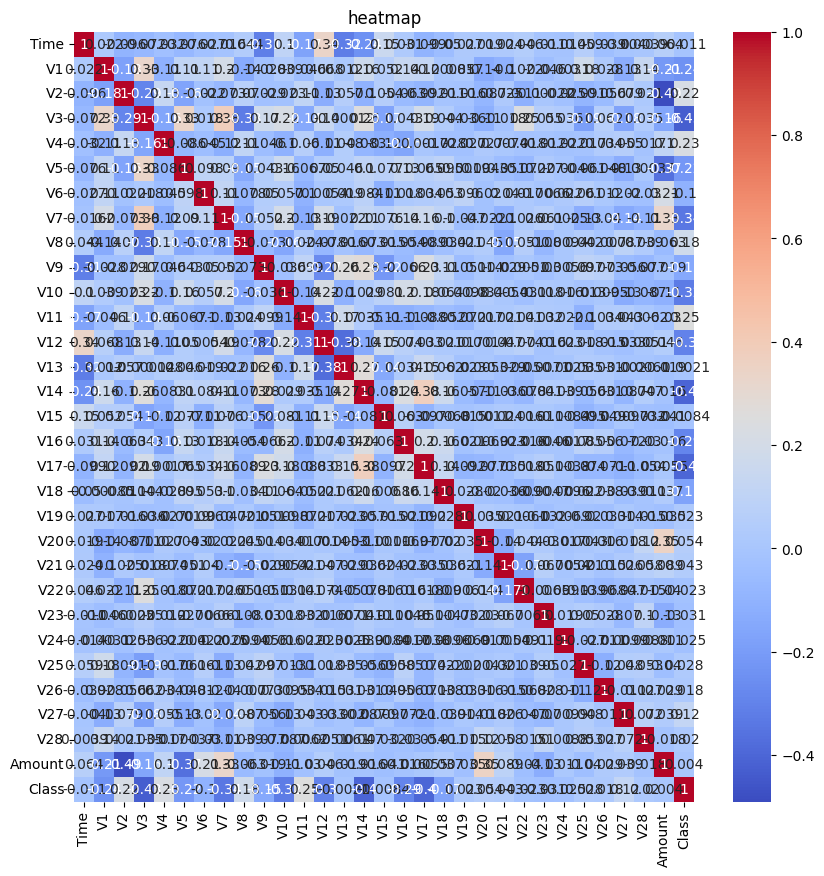

In [12]:
corr=df.corr(numeric_only=True)
plt.figure(figsize=(10,10))
sns.heatmap(corr,annot=True,cmap="coolwarm")
plt.title("heatmap")
plt.show()

In [13]:
X=df.drop("Class",axis=1)
y=df["Class"]

In [14]:
#train test split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)


In [15]:
#scaling
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)


In [16]:
#FIND BEST K USING CROSS VALIDATION
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
kvalue=range(1,8)
cv_score=[]
for k in kvalue:
  model=KNeighborsClassifier(n_neighbors=k)
  scores=cross_val_score(model,X_train,y_train,cv=5)
  cv_score.append(scores.mean())
  print(k,scores.mean())


1 0.9989513158839504
2 0.9986576565256383
3 0.9988674144671913
4 0.9988674056678816
5 0.9989093607759161
6 0.9986576653249479
7 0.9986576653249479


In [17]:
bestk=kvalue[np.argmax(cv_score)]


In [18]:
model=KNeighborsClassifier(n_neighbors=bestk)
model.fit(X_train,y_train)
y_pred=model.predict(X_test)


In [19]:
#evaluation
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
print(accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

0.9996644295302013
[[5941    0]
 [   2   17]]
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      5941
         1.0       1.00      0.89      0.94        19

    accuracy                           1.00      5960
   macro avg       1.00      0.95      0.97      5960
weighted avg       1.00      1.00      1.00      5960



In [21]:
import joblib

joblib.dump(model, "knn_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']